# Blasius Equation using Shooting Method
### AE801 Scientific Computing Lab-1

**Name :** SOUMEN SARDAR &nbsp;&nbsp;
**Roll No.:** SC26M017


**Problem:**

$$f''' + \frac{1}{2} f f'' = 0$$

Boundary conditions:
- $f(0) = 0$
- $f'(0) = 0$
- $f'(\eta) \to 1$ as $\eta \to \infty$

This is a boundary value problem (BVP). We will solve it using the shooting method.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## (a) Converting to first order system

Let
- $y_1 = f$
- $y_2 = f'$
- $y_3 = f''$

Then
- $y_1' = y_2$
- $y_2' = y_3$
- $y_3' = -\frac{1}{2} y_1 y_3$

In [ ]:
def G(y):
    y1 = y[0]
    y2 = y[1]
    y3 = y[2]
    dy1 = y2
    dy2 = y3
    dy3 = -0.5 * y1 * y3
    return np.array([dy1, dy2, dy3])

### RK3 method

$k_1 = G(y_n)$

$k_2 = G(y_n + \frac{h}{2} k_1)$

$k_3 = G(y_n - h k_1 + 2 h k_2)$

$y_{n+1} = y_n + \frac{h}{6}(k_1 + 4k_2 + k_3)$

In [ ]:
def rk3(s, h, eta_max):
    # initial conditions: f(0)=0, f'(0)=0, f''(0)=s
    y = np.array([0.0, 0.0, s])
    n = int(round(eta_max / h))

    eta_list = [0.0]
    y_list = [y]

    for i in range(n):
        k1 = G(y)
        k2 = G(y + h/2 * k1)
        k3 = G(y - h * k1 + 2 * h * k2)
        y = y + h/6 * (k1 + 4*k2 + k3)

        eta_list.append((i+1) * h)
        y_list.append(y)

    return np.array(eta_list), np.array(y_list)

## (b) Shooting parameter

At $\eta = 0$ we know $f(0) = 0$ and $f'(0) = 0$. We do not know $f''(0)$.

So we guess it. Let

$$s = f''(0)$$

We change $s$ until $f'$ becomes 1 at the far end.

## (c) Choosing $\eta_\infty$ and the residual

We cannot go up to infinity, so we take a large value. I took $\eta_\infty = 10$, because the velocity becomes almost 1 before $\eta = 6$.
Also 10 can be divided exactly by all the step sizes (0.4, 0.2, 0.1, 0.05, 0.025).

Residual:

$$F(s) = f'(\eta_\infty; s) - 1$$

In [ ]:
eta_inf = 10.0

def residual(s, h, method):
    eta, y = method(s, h, eta_inf)
    fp_end = y[-1, 1]       # f' at the last point
    return fp_end - 1

Let me first try a few values of $s$ to see where the root is.

In [ ]:
for s in [0.1, 0.2, 0.3, 0.4, 0.5]:
    print("s =", s, "  F(s) =", residual(s, 0.1, rk3))

s = 0.1   F(s) = -0.5507914218833543
s = 0.2   F(s) = -0.2868000074549605
s = 0.3   F(s) = -0.0654423962078492
s = 0.4   F(s) = 0.13213651172221774
s = 0.5   F(s) = 0.3137287501122845


$F(s)$ changes sign between $s = 0.3$ and $s = 0.4$. So the root is between them.

### Secant method

$$s_{new} = s_1 - F(s_1)\frac{s_1 - s_0}{F(s_1) - F(s_0)}$$

Tolerance = $10^{-10}$ (small enough, since we need only 3 digits).

In [ ]:
def secant(h, method, s0=0.3, s1=0.4, tol=1e-10):
    F0 = residual(s0, h, method)
    F1 = residual(s1, h, method)
    count = 0
    while abs(s1 - s0) > tol:
        s2 = s1 - F1 * (s1 - s0) / (F1 - F0)
        s0 = s1
        F0 = F1
        s1 = s2
        F1 = residual(s1, h, method)
        count = count + 1
    return s1, count

s, it = secant(0.1, rk3)
print("f''(0) =", s)
print("iterations =", it)

f''(0) = 0.33205653340091357
iterations = 5


## (d) RK3 for different step sizes

Step sizes: 0.4, 0.2, 0.1, 0.05, 0.025

To find the error, I need an "exact" value. I computed it with a very small step size ($h = 0.001$) using RK4.

In [ ]:
def rk4(s, h, eta_max):
    y = np.array([0.0, 0.0, s])
    n = int(round(eta_max / h))

    eta_list = [0.0]
    y_list = [y]

    for i in range(n):
        k1 = G(y)
        k2 = G(y + h/2 * k1)
        k3 = G(y + h/2 * k2)
        k4 = G(y + h * k3)
        y = y + h/6 * (k1 + 2*k2 + 2*k3 + k4)

        eta_list.append((i+1) * h)
        y_list.append(y)

    return np.array(eta_list), np.array(y_list)

s_exact, _ = secant(0.001, rk4)
print("Reference value of f''(0) =", s_exact)

Reference value of f''(0) = 0.3320573372037034


In [ ]:
h_values = [0.4, 0.2, 0.1, 0.05, 0.025]

s_rk3 = []
err_rk3 = []

for h in h_values:
    s, it = secant(h, rk3)
    s_rk3.append(s)
    err_rk3.append(abs(s - s_exact))

print("h        f''(0)           error")
for i in range(len(h_values)):
    print(h_values[i], "   ", round(s_rk3[i], 10), "   ", err_rk3[i])

h        f''(0)           error
0.4     0.3319771448     8.019243346790716e-05
0.2     0.3320495982     7.738955223879351e-06
0.1     0.3320565334     8.038027898282785e-07
0.05     0.3320572476     8.961176278798888e-08
0.025     0.3320573267     1.0502668512657465e-08


Order of accuracy:

$$p = \frac{\log(e_1/e_2)}{\log(h_1/h_2)}$$

In [ ]:
print("Order of RK3:")
for i in range(len(h_values) - 1):
    p = np.log(err_rk3[i] / err_rk3[i+1]) / np.log(h_values[i] / h_values[i+1])
    print("between h =", h_values[i], "and", h_values[i+1], ":  p =", round(p, 2))

Order of RK3:
between h = 0.4 and 0.2 :  p = 3.37
between h = 0.2 and 0.1 :  p = 3.27
between h = 0.1 and 0.05 :  p = 3.17
between h = 0.05 and 0.025 :  p = 3.09


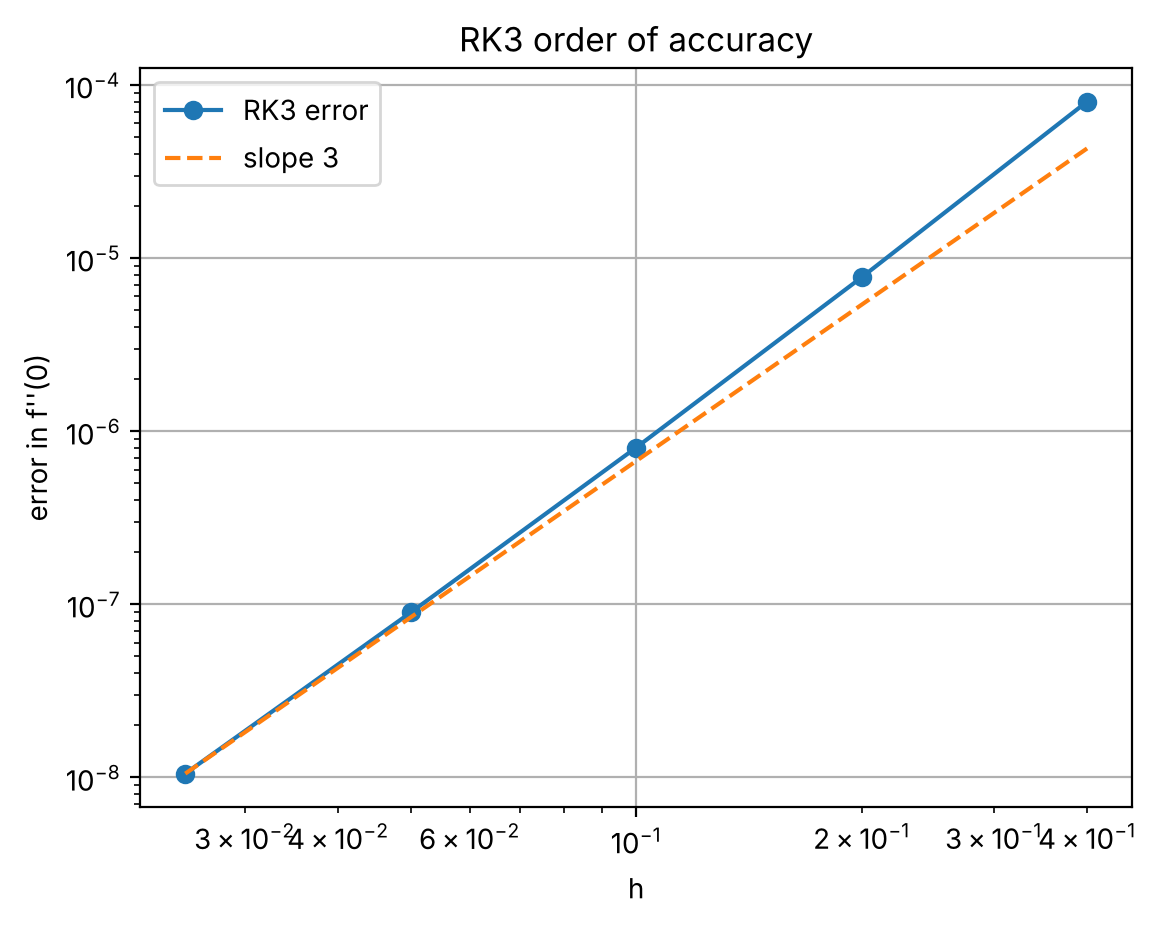

Slope of the line = 3.222929582186433


In [ ]:
plt.loglog(h_values, err_rk3, 'o-', label='RK3 error')
plt.loglog(h_values, [err_rk3[-1] * (h/0.025)**3 for h in h_values], '--', label='slope 3')
plt.xlabel('h')
plt.ylabel('error in f\'\'(0)')
plt.title('RK3 order of accuracy')
plt.legend()
plt.grid()
plt.show()

slope = np.polyfit(np.log(h_values), np.log(err_rk3), 1)[0]
print("Slope of the line =", slope)

The slope is about 3. So RK3 is third order, as expected.

## (e) Plot of $f$, $f'$, $f''$ (RK3)

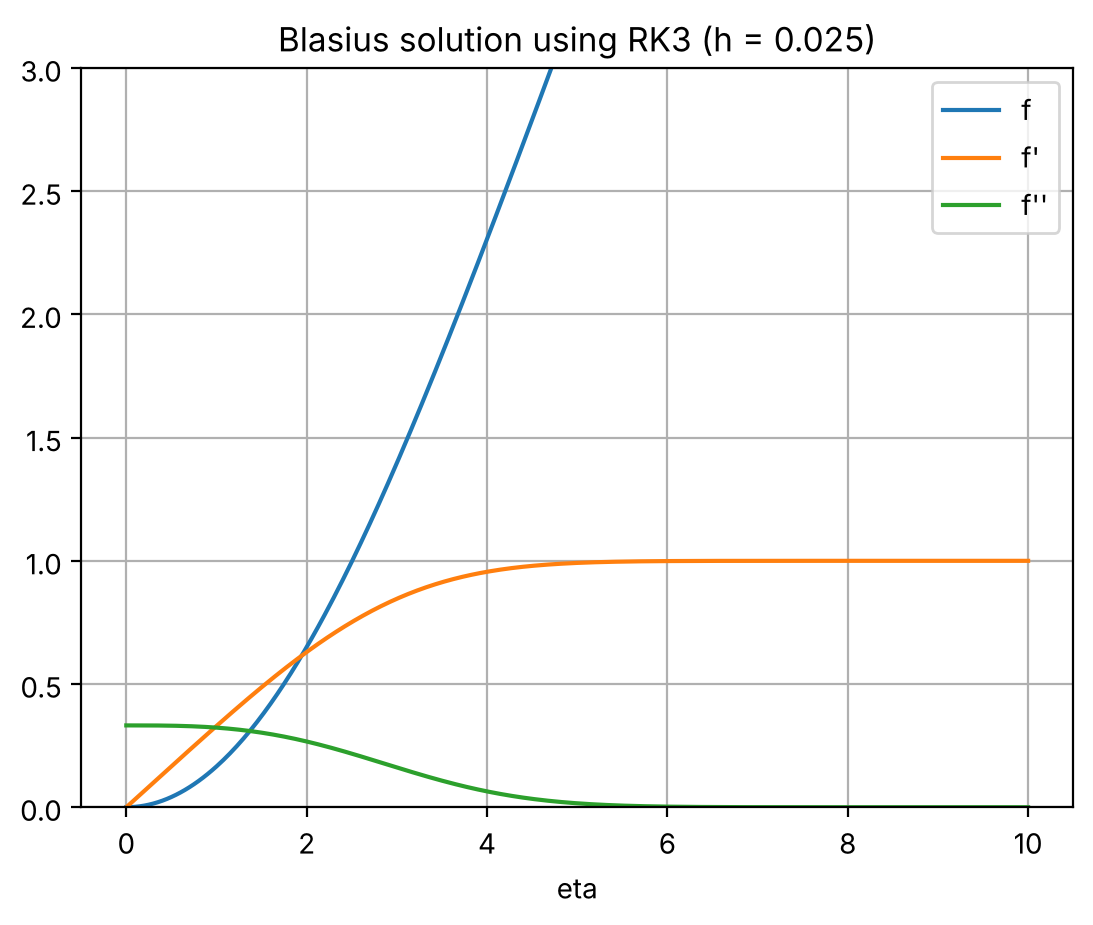

In [ ]:
eta, y = rk3(s_rk3[-1], 0.025, eta_inf)

plt.plot(eta, y[:, 0], label="f")
plt.plot(eta, y[:, 1], label="f'")
plt.plot(eta, y[:, 2], label="f''")
plt.xlabel('eta')
plt.ylim(0, 3)
plt.title('Blasius solution using RK3 (h = 0.025)')
plt.legend()
plt.grid()
plt.show()

- $f'$ goes from 0 to 1. This is the velocity profile $u/U$.
- $f''$ is maximum at the wall and goes to 0.
- $f$ becomes a straight line for large $\eta$.

## (f) Same thing using RK4

In [ ]:
s_rk4 = []
err_rk4 = []

for h in h_values:
    s, it = secant(h, rk4)
    s_rk4.append(s)
    err_rk4.append(abs(s - s_exact))

print("h        f''(0)           error")
for i in range(len(h_values)):
    print(h_values[i], "   ", round(s_rk4[i], 10), "   ", err_rk4[i])

print()
print("Order of RK4:")
for i in range(len(h_values) - 1):
    p = np.log(err_rk4[i] / err_rk4[i+1]) / np.log(h_values[i] / h_values[i+1])
    print("between h =", h_values[i], "and", h_values[i+1], ":  p =", round(p, 2))

h        f''(0)           error
0.4     0.3320588158     1.478635380247617e-06
0.2     0.3320574575     1.2024688517131565e-07
0.1     0.3320573456     8.406843499120242e-09
0.05     0.3320573378     5.535448210913785e-10
0.025     0.3320573372     3.547773186340919e-11

Order of RK4:
between h = 0.4 and 0.2 :  p = 3.62
between h = 0.2 and 0.1 :  p = 3.84
between h = 0.1 and 0.05 :  p = 3.92
between h = 0.05 and 0.025 :  p = 3.96


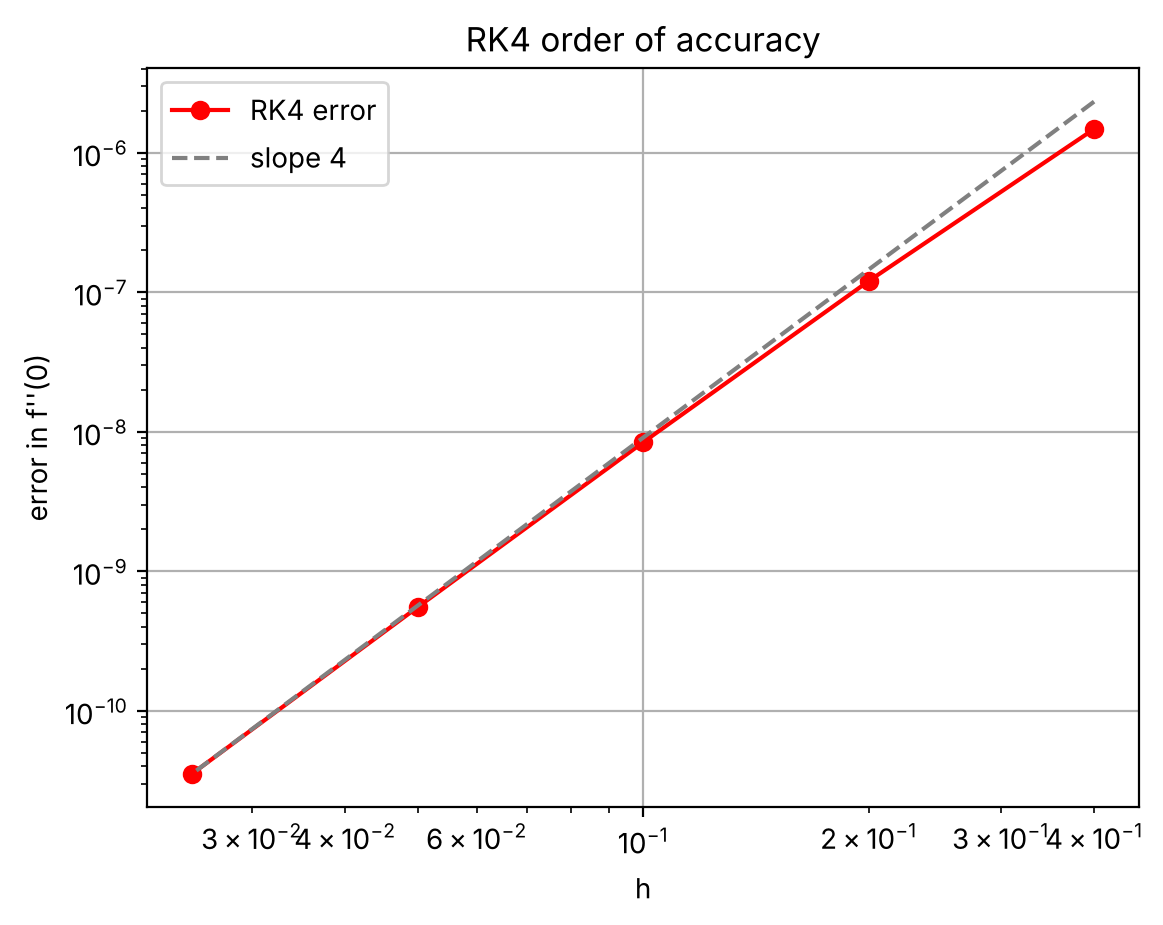

Slope of the line = 3.8457069738545746


In [ ]:
plt.loglog(h_values, err_rk4, 'o-', color='red', label='RK4 error')
plt.loglog(h_values, [err_rk4[-1] * (h/0.025)**4 for h in h_values], '--', color='gray', label='slope 4')
plt.xlabel('h')
plt.ylabel('error in f\'\'(0)')
plt.title('RK4 order of accuracy')
plt.legend()
plt.grid()
plt.show()

slope = np.polyfit(np.log(h_values), np.log(err_rk4), 1)[0]
print("Slope of the line =", slope)

The slope is about 4. So RK4 is fourth order.

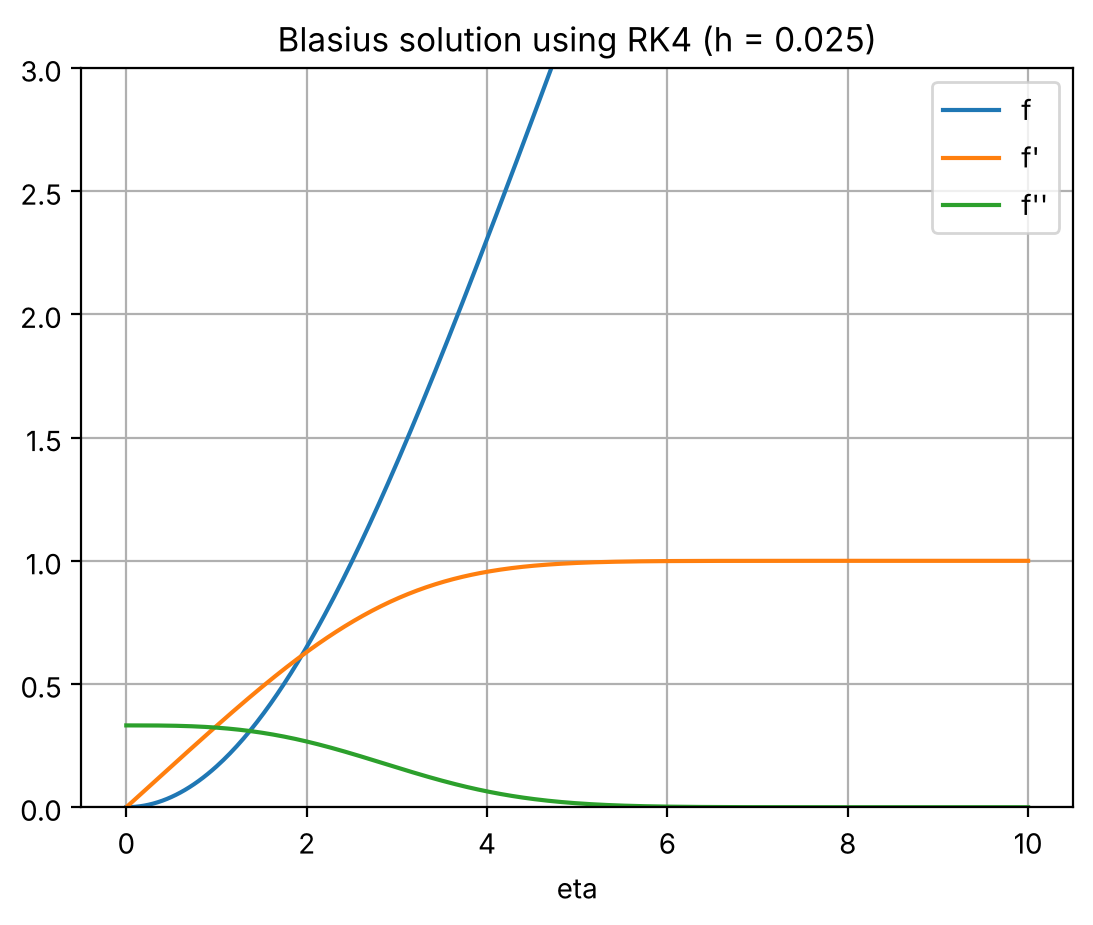

In [ ]:
eta, y = rk4(s_rk4[-1], 0.025, eta_inf)

plt.plot(eta, y[:, 0], label="f")
plt.plot(eta, y[:, 1], label="f'")
plt.plot(eta, y[:, 2], label="f''")
plt.xlabel('eta')
plt.ylim(0, 3)
plt.title('Blasius solution using RK4 (h = 0.025)')
plt.legend()
plt.grid()
plt.show()

Comparing both errors on one plot:

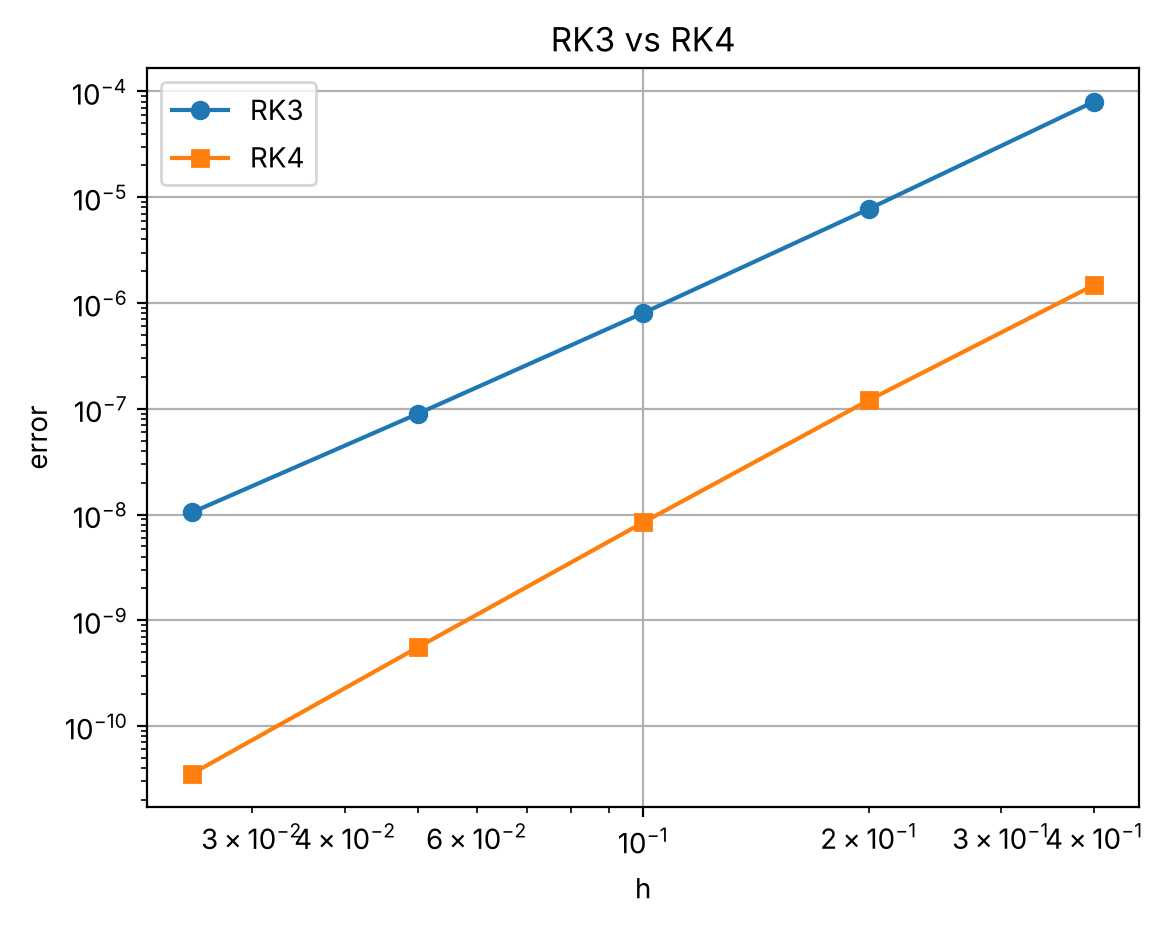

In [ ]:
plt.loglog(h_values, err_rk3, 'o-', label='RK3')
plt.loglog(h_values, err_rk4, 's-', label='RK4')
plt.xlabel('h')
plt.ylabel('error')
plt.title('RK3 vs RK4')
plt.legend()
plt.grid()
plt.show()

RK4 has much smaller error than RK3 for the same step size.

## (g) Check

In [ ]:
print("RK3 (h = 0.025): f''(0) =", round(s_rk3[-1], 3))
print("RK4 (h = 0.025): f''(0) =", round(s_rk4[-1], 3))
print("Expected value          = 0.332")

RK3 (h = 0.025): f''(0) = 0.332
RK4 (h = 0.025): f''(0) = 0.332
Expected value          = 0.332


Both give $f''(0) = 0.332$, which matches the expected value to three digits.

## Conclusion

1. The Blasius equation was converted into 3 first order equations.
2. The unknown $f''(0)$ was found using the shooting method with the secant method.
3. RK3 showed order about 3 and RK4 showed order about 4.
4. The final answer is $f''(0) \approx 0.332$, which is correct.